# Cultural Policies and Measures — Exploratory Analysis

Dataset: `dce002.parquet` — 8,155 cultural policies and measures reported by parties to the UNESCO 2005 Convention on the Protection and Promotion of the Diversity of Cultural Expressions.

## Data source & attribution

- **Source:** [UNESCO DataHub — Cultural Policies and Measures (`dce002`)](https://data.unesco.org/explore/assets/dce002/)
- **Publisher:** UNESCO
- **License:** [Open Access](https://www.unesco.org/en/open-access)
- **Last modified (source):** 2026-09-17
- **Local snapshot used here:** `dce002.parquet`, 8,155 records

**Description:** The dataset compiles cultural policies and measures submitted by parties to the UNESCO 2005 Convention on cultural diversity. These government-reported policies emphasize efforts to support cultural diversity through periodic reports, including implementation details and outcomes.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from shapely import wkb

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

## 1. Load the data

In [2]:
df = pd.read_parquet("datasets/dce002.parquet")
print(df.shape)
df.head()

(8155, 30)


,id,uuid,title_en,date,countries,goal,sdg,area_monitoring,cultural_domain,agency_implementation,...,documentid,publishedat,website,main_image,document,strapi_stage,strapi_assignee,country_title_en,regional_group,coordinates
0,4717,6f2907fc-cf62-4686-8fa0-f97496bcab48,"""chile in the world"" programme",2016-01-01,CL,Achieve A Balanced Flow Of Cultural Goods And ...,"SDG 8 - Promote sustained, inclusive and susta...","Flow of cultural goods and services,Mobility o...",None,National council for culture and arts,...,a251yzk8f6yavj3ucl3zaiwn,2026-01-29 19:05:00+11:00,None,"{'id': 5662045, 'title': '', 'copyright': None...","{'id': 168887, 'title': '', 'url': 'uml://webf...",None,None,Chile,Latin America and the Caribbean,b'\x01\x01\x00\x00\x00\x9a\x99\x99\x99\x99\xa9...
1,4726,3afc6230-e9f5-4b7e-b91e-10e1ad728272,"""cultural observatory, a space for the analysi...",2020-01-01,CL,Support Sustainable Systems Of Governance For ...,SDG 4 - Ensure inclusive and equitable quality...,National sustainable development policies and ...,"Cinema and Audiovisual Arts,Design,Media Arts,...","Ministry of cultures, arts and heritage (minca...",...,wbwer6lrwtradi5lkrm1r9vj,2026-01-29 19:05:02+11:00,"{'id': 4495742, 'url': 'http://observatorio.cu...","{'id': 5662054, 'title': '', 'copyright': None...","{'id': 168896, 'title': '', 'url': 'uml://webf...",None,None,Chile,Latin America and the Caribbean,b'\x01\x01\x00\x00\x00\x9a\x99\x99\x99\x99\xa9...
2,4729,7fd91fa2-1b6f-431d-97a7-51cee1eda0c8,"""current regulatory framework of creative acti...",2020-01-01,CL,Support Sustainable Systems Of Governance For ...,SDG 4 - Ensure inclusive and equitable quality...,National sustainable development policies and ...,None,"Mincap, minecon, cntv, minrel, etc.",...,ikvcp0liztiwn0yjlr2cuvpy,2026-01-29 19:05:02+11:00,"{'id': 4495745, 'url': 'https://www.leychile.c...","{'id': 5662057, 'title': '', 'copyright': None...","{'id': 168899, 'title': '', 'url': 'uml://webf...",None,None,Chile,Latin America and the Caribbean,b'\x01\x01\x00\x00\x00\x9a\x99\x99\x99\x99\xa9...
3,4731,3c57b097-799d-430c-9b32-9dcb0d0dd312,"""day of cultural diversity for dialogue and de...",2020-01-01,CL,Support Sustainable Systems Of Governance For ...,SDG 4 - Ensure inclusive and equitable quality...,National sustainable development policies and ...,None,"Ministry of cultures, arts and heritage (mincap).",...,eycey47o60jry2m37kavceog,2026-01-29 19:05:03+11:00,"{'id': 4495747, 'url': 'https://www.leychile.c...","{'id': 5662059, 'title': '', 'copyright': None...","{'id': 168901, 'title': '', 'url': 'uml://webf...",None,None,Chile,Latin America and the Caribbean,b'\x01\x01\x00\x00\x00\x9a\x99\x99\x99\x99\xa9...
4,4737,ff388c54-9e28-4fbb-96b6-147994d60f92,"""flows and barriers to trade in cultural goods...",2020-01-01,CL,Achieve A Balanced Flow Of Cultural Goods And ...,"SDG 8 - Promote sustained, inclusive and susta...","Flow of cultural goods and services,Mobility o...",None,It is a measure taken by the pacific alliance ...,...,nfcm49xtodvvk1u75shhmizh,2026-01-29 19:05:04+11:00,"{'id': 4495753, 'url': 'https://culturayeconom...","{'id': 5662065, 'title': '', 'copyright': None...","{'id': 168907, 'title': '', 'url': 'uml://webf...",None,None,Chile,Latin America and the Caribbean,b'\x01\x01\x00\x00\x00\x9a\x99\x99\x99\x99\xa9...


## 2. Select useable columns for analysis

Drop internal workflow/administrative fields (`createdat`, `updatedat`, `documentid`, `publishedat`, `main_image`, `strapi_stage`, `strapi_assignee`) that aren't relevant to content analysis.

In [3]:
USEABLE_COLUMNS = [
    "id",
    "title_en",
    "date",
    "country_title_en",
    "countries",
    "regional_group",
    "goal",
    "sdg",
    "area_monitoring",
    "cultural_domain",
    "agency_implementation",
    "main_feature",
    "results",
    "financial_ressources",
    "recommandations",
    "ifcd",
    "young_people",
    "evaluation",
    "cso",
    "website",
    "document",
    "coordinates",
]

df = df[USEABLE_COLUMNS].rename(columns={"country_title_en": "country","countries": "iso_codes","regional_group": "region"})
print(df.shape)
df.head()

(8155, 22)


,id,title_en,date,country,iso_codes,region,goal,sdg,area_monitoring,cultural_domain,...,results,financial_ressources,recommandations,ifcd,young_people,evaluation,cso,website,document,coordinates
0,4717,"""chile in the world"" programme",2016-01-01,Chile,CL,Latin America and the Caribbean,Achieve A Balanced Flow Of Cultural Goods And ...,"SDG 8 - Promote sustained, inclusive and susta...","Flow of cultural goods and services,Mobility o...",None,...,"The initiative is linked to the financing, pro...",Total budget 2016: 542.246.000 chilean pesos.,None,False,False,False,False,None,"{'id': 168887, 'title': '', 'url': 'uml://webf...",b'\x01\x01\x00\x00\x00\x9a\x99\x99\x99\x99\xa9...
1,4726,"""cultural observatory, a space for the analysi...",2020-01-01,Chile,CL,Latin America and the Caribbean,Support Sustainable Systems Of Governance For ...,SDG 4 - Ensure inclusive and equitable quality...,National sustainable development policies and ...,"Cinema and Audiovisual Arts,Design,Media Arts,...",...,None,None,No information.,False,False,False,False,"{'id': 4495742, 'url': 'http://observatorio.cu...","{'id': 168896, 'title': '', 'url': 'uml://webf...",b'\x01\x01\x00\x00\x00\x9a\x99\x99\x99\x99\xa9...
2,4729,"""current regulatory framework of creative acti...",2020-01-01,Chile,CL,Latin America and the Caribbean,Support Sustainable Systems Of Governance For ...,SDG 4 - Ensure inclusive and equitable quality...,National sustainable development policies and ...,None,...,None,None,No information.,False,False,False,False,"{'id': 4495745, 'url': 'https://www.leychile.c...","{'id': 168899, 'title': '', 'url': 'uml://webf...",b'\x01\x01\x00\x00\x00\x9a\x99\x99\x99\x99\xa9...
3,4731,"""day of cultural diversity for dialogue and de...",2020-01-01,Chile,CL,Latin America and the Caribbean,Support Sustainable Systems Of Governance For ...,SDG 4 - Ensure inclusive and equitable quality...,National sustainable development policies and ...,None,...,None,None,No information.,False,False,False,False,"{'id': 4495747, 'url': 'https://www.leychile.c...","{'id': 168901, 'title': '', 'url': 'uml://webf...",b'\x01\x01\x00\x00\x00\x9a\x99\x99\x99\x99\xa9...
4,4737,"""flows and barriers to trade in cultural goods...",2020-01-01,Chile,CL,Latin America and the Caribbean,Achieve A Balanced Flow Of Cultural Goods And ...,"SDG 8 - Promote sustained, inclusive and susta...","Flow of cultural goods and services,Mobility o...",None,...,Based on the review of the barriers presented ...,None,No information.,False,False,False,False,"{'id': 4495753, 'url': 'https://culturayeconom...","{'id': 168907, 'title': '', 'url': 'uml://webf...",b'\x01\x01\x00\x00\x00\x9a\x99\x99\x99\x99\xa9...


## 3. Extract year from `date`

In [4]:
df["year"] = pd.to_datetime(df["date"], errors="coerce").dt.year

before = len(df)
df = df[df["year"].notna()].copy()
after = len(df)
print(f"Dropped {before - after} row(s) without a valid year; {after} remain")

df["year"] = df["year"].astype(int)
df["year"].describe()

Dropped 0 row(s) without a valid year; 8155 remain


count    8155.000000
mean     2020.538443
std         3.596845
min      2012.000000
25%      2019.000000
50%      2020.000000
75%      2024.000000
max      2024.000000
Name: year, dtype: float64

## 4. Validate boolean flags

`ifcd`, `young_people`, `evaluation`, and `cso` should each be exactly `True` or `False`; drop anything else.

In [5]:
BOOLEAN_FLAGS = ["ifcd", "young_people", "evaluation", "cso"]

before = len(df)
for flag in BOOLEAN_FLAGS:
    df = df[df[flag].isin(["True", "False"])].copy()
after = len(df)
print(f"Dropped {before - after} row(s) with an invalid boolean flag; {after} remain")

df[BOOLEAN_FLAGS].apply(pd.Series.value_counts)

Dropped 0 row(s) with an invalid boolean flag; 8155 remain


,ifcd,young_people,evaluation,cso
False,7964,6716,6168,6957
True,191,1439,1987,1198


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 8155 entries, 0 to 8154
Data columns (total 23 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   id                     8155 non-null   int64 
 1   title_en               8155 non-null   object
 2   date                   8155 non-null   object
 3   country                8013 non-null   object
 4   iso_codes              8155 non-null   object
 5   region                 8013 non-null   object
 6   goal                   8155 non-null   object
 7   sdg                    8155 non-null   object
 8   area_monitoring        8155 non-null   object
 9   cultural_domain        5650 non-null   object
 10  agency_implementation  7670 non-null   object
 11  main_feature           7775 non-null   object
 12  results                6809 non-null   object
 13  financial_ressources   3920 non-null   object
 14  recommandations        2170 non-null   object
 15  ifcd                 

## 5. Missing values

In [7]:
missing_pct = (df.isna().mean() * 100).sort_values(ascending=False)
missing_pct[missing_pct > 0]

recommandations          73.390558
financial_ressources     51.931330
website                  44.561619
document                 41.802575
cultural_domain          30.717351
results                  16.505212
agency_implementation     5.947272
main_feature              4.659718
coordinates               1.741263
country                   1.741263
region                    1.741263
dtype: float64

## 6. Policy goals (2005 Convention)

`goal` can list more than one value per record (comma-separated), so explode before counting.

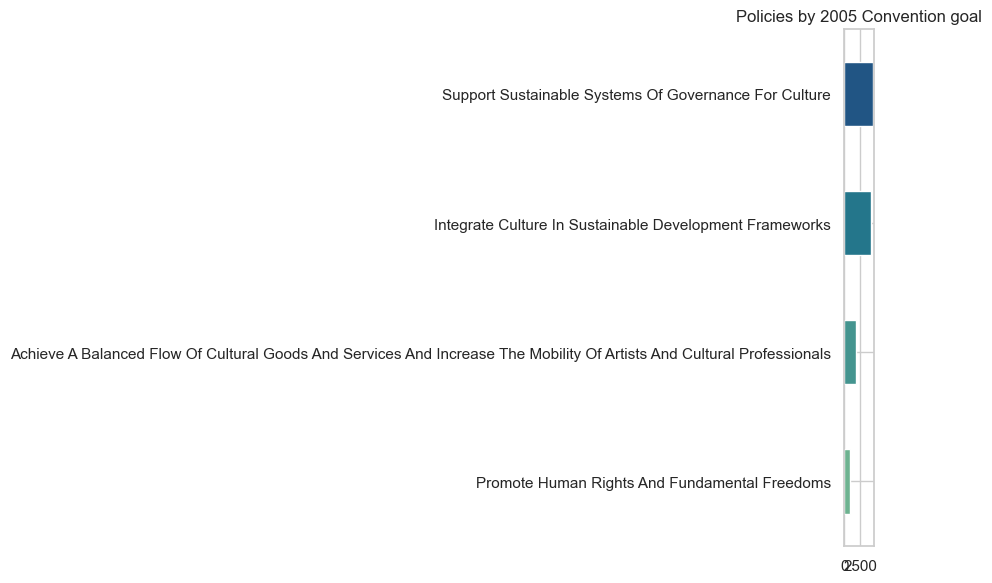

In [8]:
goal_counts = df["goal"].dropna().str.split(",").explode().str.strip().value_counts()

fig, ax = plt.subplots(figsize=(9, 6))
goal_counts.sort_values().plot(kind="barh", ax=ax, color=sns.color_palette("crest", len(goal_counts)))
ax.set_title("Policies by 2005 Convention goal")
plt.tight_layout()
plt.show()

## 7. Sustainable Development Goal (SDG) alignment

`sdg` entries are long descriptive strings (e.g. `"SDG 8 - Promote sustained..."`) — keep just the `SDG n` label before exploding.

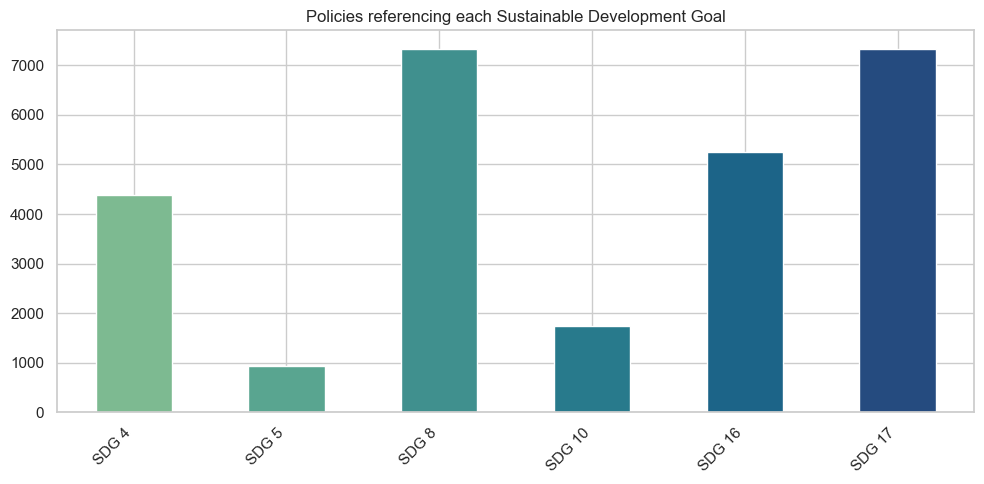

In [9]:
sdg_labels = (
    df["sdg"].dropna().str.split(",").explode().str.extract(r"(SDG \d+)", expand=False).dropna()
)
sdg_counts = sdg_labels.value_counts().sort_index(key=lambda idx: idx.str.extract(r"(\d+)")[0].astype(int))

fig, ax = plt.subplots(figsize=(10, 5))
sdg_counts.plot(kind="bar", ax=ax, color=sns.color_palette("crest", len(sdg_counts)))
ax.set_title("Policies referencing each Sustainable Development Goal")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## 8. Cultural domains covered

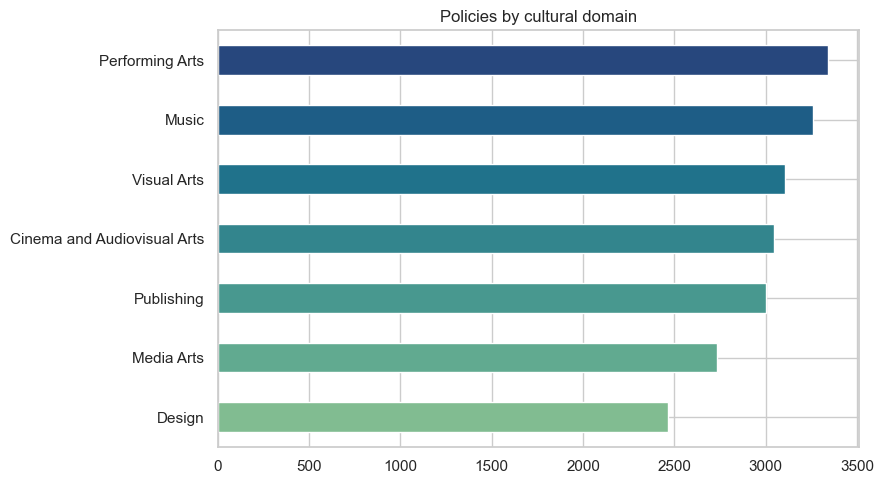

In [10]:
domain_counts = df["cultural_domain"].dropna().str.split(",").explode().str.strip().value_counts()

fig, ax = plt.subplots(figsize=(9, 5))
domain_counts.sort_values().plot(kind="barh", ax=ax, color=sns.color_palette("crest", len(domain_counts)))
ax.set_title("Policies by cultural domain")
plt.tight_layout()
plt.show()

## 9. Monitoring areas

Some records repeat the same monitoring area within `area_monitoring` — dedupe per row before counting.

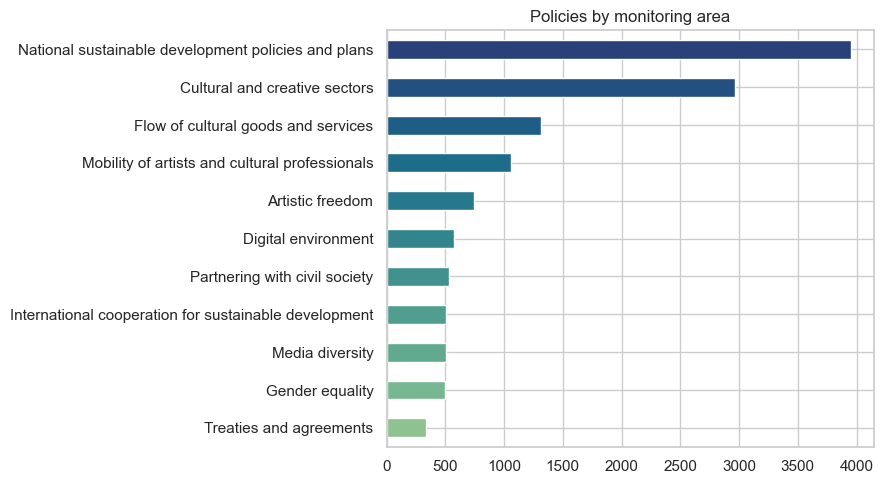

In [11]:
def unique_values(value):
    if pd.isna(value):
        return np.nan
    return ",".join(dict.fromkeys(part.strip() for part in value.split(",")))

area_counts = df["area_monitoring"].apply(unique_values).dropna().str.split(",").explode().value_counts()

fig, ax = plt.subplots(figsize=(9, 5))
area_counts.sort_values().plot(kind="barh", ax=ax, color=sns.color_palette("crest", len(area_counts)))
ax.set_title("Policies by monitoring area")
plt.tight_layout()
plt.show()

## 10. Policies reported over time

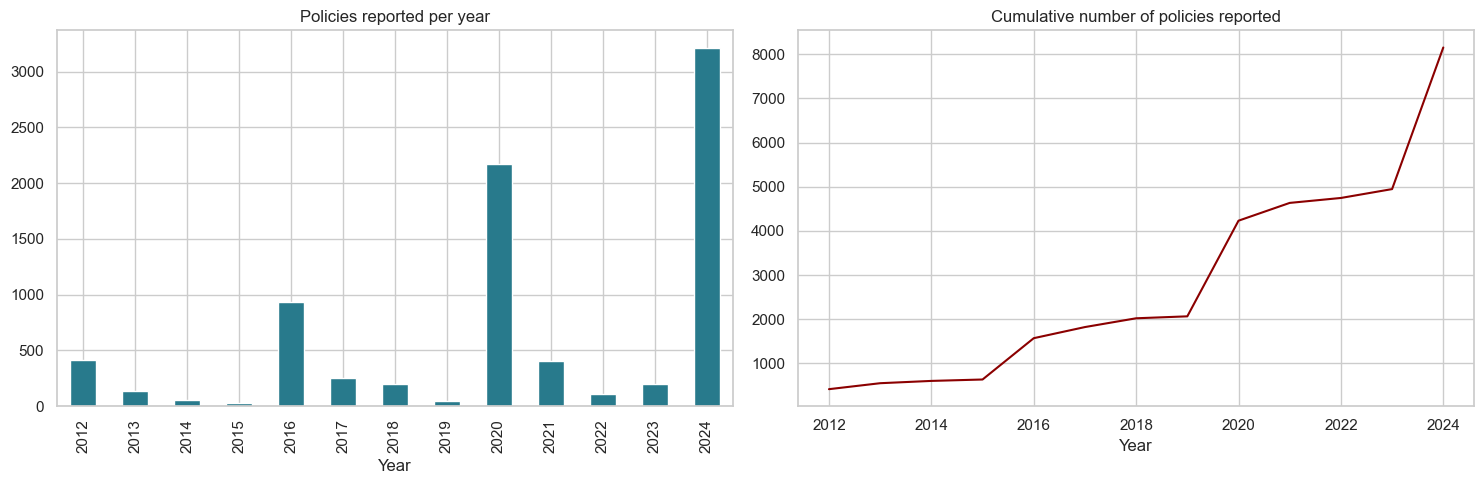

In [12]:
by_year = df["year"].value_counts().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

by_year.plot(kind="bar", ax=axes[0], color=sns.color_palette("crest")[3])
axes[0].set_title("Policies reported per year")
axes[0].set_xlabel("Year")

by_year.cumsum().plot(ax=axes[1], color="darkred")
axes[1].set_title("Cumulative number of policies reported")
axes[1].set_xlabel("Year")

plt.tight_layout()
plt.show()

## 11. Top countries by number of policies

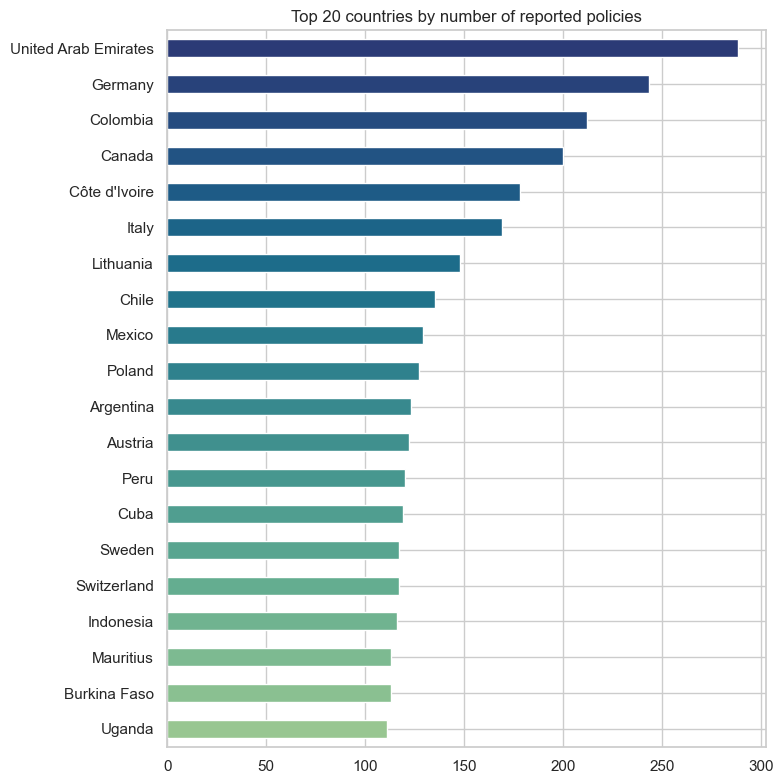

In [13]:
top_countries = df["country"].value_counts().head(20)

fig, ax = plt.subplots(figsize=(8, 8))
top_countries.sort_values().plot(kind="barh", ax=ax, color=sns.color_palette("crest", 20))
ax.set_title("Top 20 countries by number of reported policies")
plt.tight_layout()
plt.show()

## 12. IFCD funding, youth focus & civil society involvement

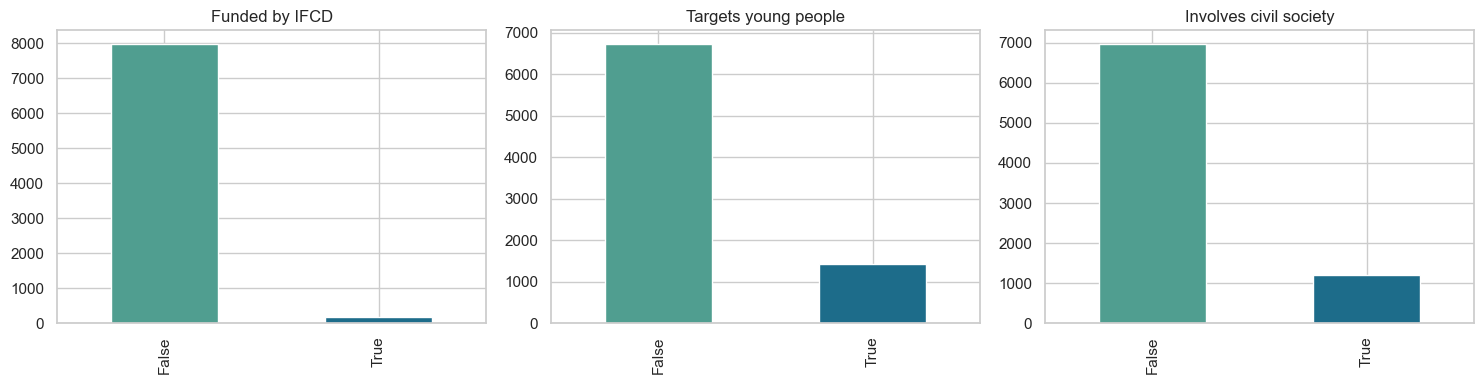

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col, title in zip(
    axes,
    ["ifcd", "young_people", "cso"],
    ["Funded by IFCD", "Targets young people", "Involves civil society"],
):
    df[col].value_counts().plot(kind="bar", ax=ax, color=sns.color_palette("crest", 2))
    ax.set_title(title)
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

## 13. Geographic distribution

`coordinates` is stored as WKB (well-known binary) point geometry — decode it with `shapely` to get lat/lon.

8013 of 8155 records have coordinates


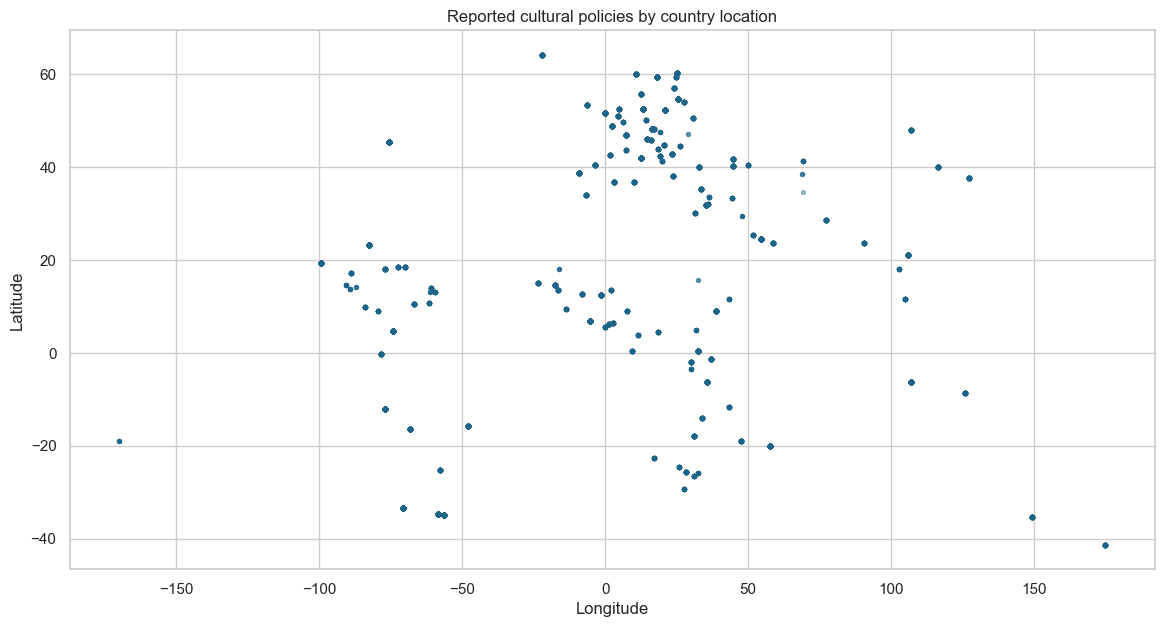

In [15]:
def decode_point(geom):
    if geom is None:
        return pd.Series({"lat": np.nan, "lon": np.nan})
    p = wkb.loads(geom)
    return pd.Series({"lat": p.y, "lon": p.x})

df[["lat", "lon"]] = df["coordinates"].apply(decode_point)
print(f"{df['lat'].notna().sum()} of {len(df)} records have coordinates")

fig, ax = plt.subplots(figsize=(14, 7))
ax.scatter(df["lon"], df["lat"], s=8, alpha=0.4, color=sns.color_palette("crest")[4])
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Reported cultural policies by country location")
plt.show()

## 14. Export cleaned data to CSV

In [16]:
output_path = "datasets/dce002_cleaned.csv"
df = df.drop(columns=['coordinates','date'])
df.to_csv(output_path, index=False)
print(f"Saved {len(df)} rows x {df.shape[1]} columns to {output_path}")

Saved 8155 rows x 23 columns to datasets/dce002_cleaned.csv


## Next steps

Ideas to extend this analysis:
- Text-mine `main_feature` / `results` / `recommandations` for common themes per goal or domain.
- Cross-tabulate `ifcd` funding against `results`/`evaluation` to see whether funded policies report stronger outcomes.
- Join against [`mhm001`](mhm001.ipynb) (National Cultural Heritage Laws) by country to compare legislative vs. policy activity.
- Track `financial_ressources` (where populated) to estimate reported investment by domain or region.